# Comparación de modelos de clasificación de riesgo

## Proyecto

**VitalMind AI**


## Objetivo

Comparar visualmente los resultados iniciales de los modelos de clasificación de riesgo entrenados con datos sintéticos.

Los modelos evaluados son:

- Regresión Logística.
- Random Forest Classifier.

La comparación utilizará exclusivamente el conjunto de validación.

El conjunto de prueba permanecerá reservado hasta finalizar la selección y el ajuste del mejor modelo.

## 1. Archivos utilizados

Este notebook utilizará los siguientes artefactos:

```text
ml-service/reports/classification/initial_validation_metrics.json
ml-service/reports/classification/initial_model_comparison.csv
ml-service/reports/classification/validation_predictions.csv
```

También se cargarán los modelos serializados únicamente para revisar su estructura:

```text
ml-service/app/models/risk-classification/
```


In [1]:
from pathlib import Path
import json
import warnings

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    ConfusionMatrixDisplay,
    confusion_matrix,
)

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda value: f"{value:,.4f}")

print("Librerías importadas correctamente.")

Librerías importadas correctamente.


## 2. Definición de rutas

Se utilizarán rutas relativas para evitar depender de la ubicación absoluta del repositorio.

In [5]:
NOTEBOOK_DIR = Path.cwd()

if NOTEBOOK_DIR.name == "notebooks":
    ML_SERVICE_DIR = NOTEBOOK_DIR.parent
elif (NOTEBOOK_DIR / "ml-service").exists():
    ML_SERVICE_DIR = NOTEBOOK_DIR / "ml-service"
else:
    ML_SERVICE_DIR = NOTEBOOK_DIR.parent

REPORTS_DIR = (
    ML_SERVICE_DIR
    /".."
    / "reports"
    / "classification"
)

MODELS_DIR = (
    ML_SERVICE_DIR
    /".."
    / "app"
    / "models"
    / "risk-classification"
)

METRICS_PATH = (
    REPORTS_DIR
    
    / "initial_validation_metrics.json"
)

COMPARISON_PATH = (
    REPORTS_DIR

    / "initial_model_comparison.csv"
)

PREDICTIONS_PATH = (
    REPORTS_DIR
    / "validation_predictions.csv"
)

LOGISTIC_MODEL_PATH = (
    MODELS_DIR
    / "logistic_regression_pipeline.joblib"
)

RANDOM_FOREST_MODEL_PATH = (
    MODELS_DIR
    / "random_forest_pipeline.joblib"
)

LABEL_ENCODER_PATH = (
    MODELS_DIR
    / "risk_label_encoder.joblib"
)

paths = {
    "Métricas": METRICS_PATH,
    "Comparación": COMPARISON_PATH,
    "Predicciones": PREDICTIONS_PATH,
    "Regresión Logística": LOGISTIC_MODEL_PATH,
    "Random Forest": RANDOM_FOREST_MODEL_PATH,
    "Label Encoder": LABEL_ENCODER_PATH,
}

for name, path in paths.items():
    print(f"{name}: {path.exists()} — {path}")

Métricas: True — C:\Users\otero\OneDrive\Desktop\9A-IDGS-ECBD-VitalMind-\ml-service\app\..\reports\classification\initial_validation_metrics.json
Comparación: True — C:\Users\otero\OneDrive\Desktop\9A-IDGS-ECBD-VitalMind-\ml-service\app\..\reports\classification\initial_model_comparison.csv
Predicciones: True — C:\Users\otero\OneDrive\Desktop\9A-IDGS-ECBD-VitalMind-\ml-service\app\..\reports\classification\validation_predictions.csv
Regresión Logística: True — C:\Users\otero\OneDrive\Desktop\9A-IDGS-ECBD-VitalMind-\ml-service\app\..\app\models\risk-classification\logistic_regression_pipeline.joblib
Random Forest: True — C:\Users\otero\OneDrive\Desktop\9A-IDGS-ECBD-VitalMind-\ml-service\app\..\app\models\risk-classification\random_forest_pipeline.joblib
Label Encoder: True — C:\Users\otero\OneDrive\Desktop\9A-IDGS-ECBD-VitalMind-\ml-service\app\..\app\models\risk-classification\risk_label_encoder.joblib


## 3. Carga de métricas, comparación y predicciones

In [6]:
with METRICS_PATH.open(
    "r",
    encoding="utf-8",
) as metrics_file:
    metrics_data = json.load(metrics_file)

comparison_df = pd.read_csv(COMPARISON_PATH)
predictions_df = pd.read_csv(PREDICTIONS_PATH)

label_encoder = joblib.load(LABEL_ENCODER_PATH)

print("Archivos cargados correctamente.")
print(f"Modelos evaluados: {len(metrics_data)}")
print(f"Filas en comparación: {len(comparison_df)}")
print(f"Predicciones registradas: {len(predictions_df):,}")
print(f"Clases: {label_encoder.classes_.tolist()}")

Archivos cargados correctamente.
Modelos evaluados: 2
Filas en comparación: 2
Predicciones registradas: 1,462
Clases: ['high', 'low', 'medium']


In [7]:
comparison_df

,model,accuracy,precision_weighted,recall_weighted,f1_weighted,f1_macro,roc_auc_weighted_ovr
0,logistic_regression,0.8933,0.8935,0.8933,0.8929,0.8933,0.9771
1,random_forest,0.8824,0.8826,0.8824,0.8821,0.8825,0.9701


## 4. Resumen inicial de resultados

La tabla contiene las métricas globales calculadas sobre el conjunto de validación:

- Accuracy.
- Presicion ponderada.
- Recall ponderada.
- F1 ponderado.
- F1 macro.
- ROC-AUC multiclase.

In [8]:
with METRICS_PATH.open(
    "r",
    encoding="utf-8",
) as metrics_file:
    metrics_data = json.load(metrics_file)

comparison_df = pd.read_csv(COMPARISON_PATH)
predictions_df = pd.read_csv(PREDICTIONS_PATH)

label_encoder = joblib.load(LABEL_ENCODER_PATH)

print("Archivos cargados correctamente.")
print(f"Modelos evaluados: {len(metrics_data)}")
print(f"Filas en comparación: {len(comparison_df)}")
print(f"Predicciones registradas: {len(predictions_df):,}")
print(f"Clases: {label_encoder.classes_.tolist()}")

Archivos cargados correctamente.
Modelos evaluados: 2
Filas en comparación: 2
Predicciones registradas: 1,462
Clases: ['high', 'low', 'medium']


In [9]:
comparison_display = (
    comparison_df[
        [
            "model",
            "accuracy",
            "precision_weighted",
            "recall_weighted",
            "f1_weighted",
            "f1_macro",
            "roc_auc_weighted_ovr",
        ]
    ]
    .copy()
    .sort_values(
        by="f1_macro",
        ascending=False,
    )
)

comparison_display

,model,accuracy,precision_weighted,recall_weighted,f1_weighted,f1_macro,roc_auc_weighted_ovr
0,logistic_regression,0.8933,0.8935,0.8933,0.8929,0.8933,0.9771
1,random_forest,0.8824,0.8826,0.8824,0.8821,0.8825,0.9701


In [10]:
best_model_row = comparison_display.iloc[0]

print("Mejor modelo provisional:")
print(best_model_row["model"])

print("\nMétricas principales:")
print(f"Accuracy: {best_model_row['accuracy']:.4f}")
print(f"F1 macro: {best_model_row['f1_macro']:.4f}")
print(
    "ROC-AUC ponderado: "
    f"{best_model_row['roc_auc_weighted_ovr']:.4f}"
)

Mejor modelo provisional:
logistic_regression

Métricas principales:
Accuracy: 0.8933
F1 macro: 0.8933
ROC-AUC ponderado: 0.9771


## 5. Comparación visual de métricas globales

Se compararán los modelos utilizando las principales métricas de clasificación.

F1 macro tendrá especial importancia porque asigna el mismo peso a cada clase, independientemente de su frecuencia.

<Figure size 1100x600 with 0 Axes>

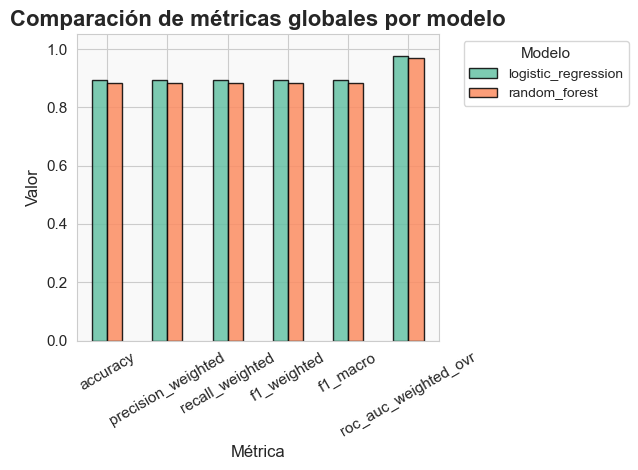

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
sns.set_palette("muted")

plt.figure(figsize=(11,6))

ax = metrics_for_plot.plot(
    kind="bar",
    color=sns.color_palette("Set2", len(metrics_for_plot.columns)),
    edgecolor="black",
    alpha=0.85
)

# Títulos y etiquetas llamativas
ax.set_title("Comparación de métricas globales por modelo", fontsize=16, fontweight="bold")
ax.set_xlabel("Métrica", fontsize=12)
ax.set_ylabel("Valor", fontsize=12)

# Ajuste de ticks
ax.tick_params(axis="x", rotation=30, labelsize=11)
ax.tick_params(axis="y", labelsize=11)

# Límites claros
ax.set_ylim(0, 1.05)

# Leyenda estilizada
ax.legend(title="Modelo", fontsize=10, title_fontsize=11, bbox_to_anchor=(1.05, 1), loc="upper left")

# Fondo claro
plt.gca().set_facecolor("#f9f9f9")

plt.tight_layout()
plt.show()


<Figure size 800x400 with 0 Axes>

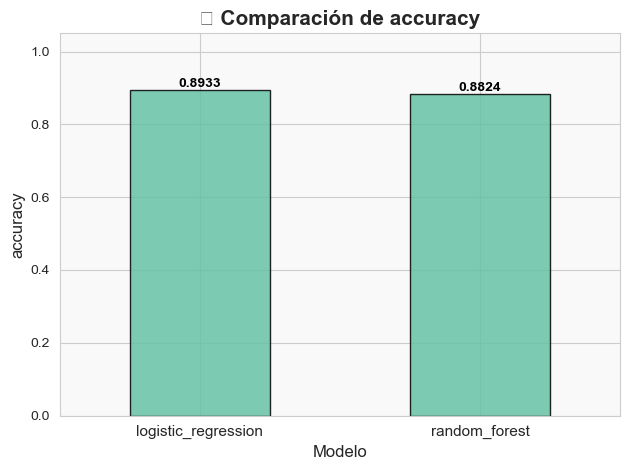

<Figure size 800x400 with 0 Axes>

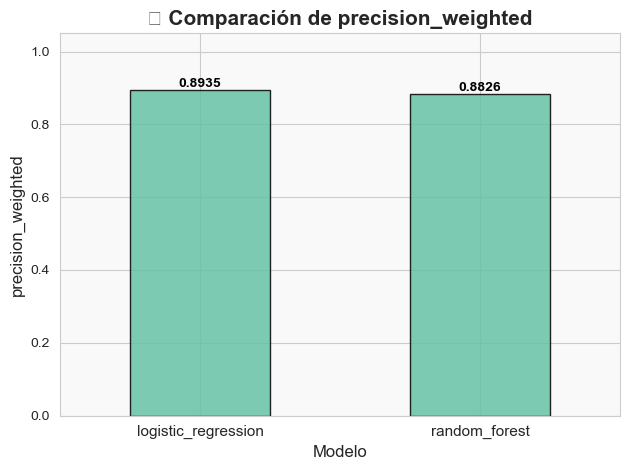

<Figure size 800x400 with 0 Axes>

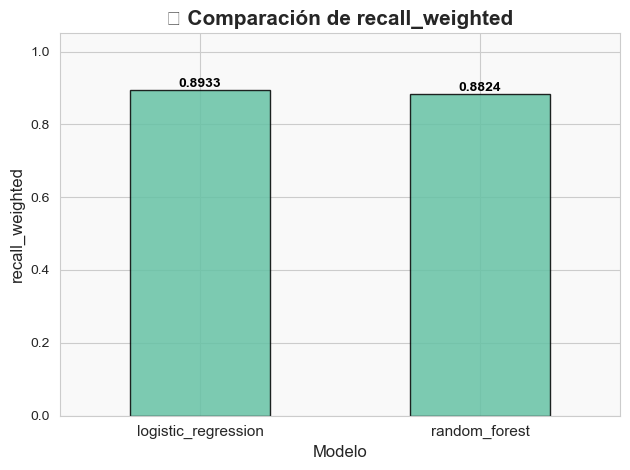

<Figure size 800x400 with 0 Axes>

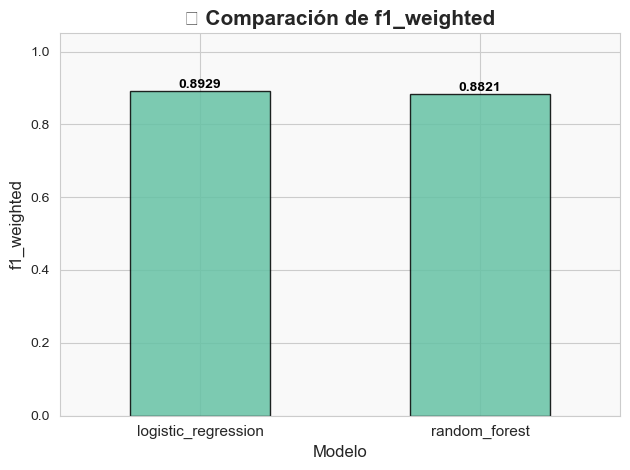

<Figure size 800x400 with 0 Axes>

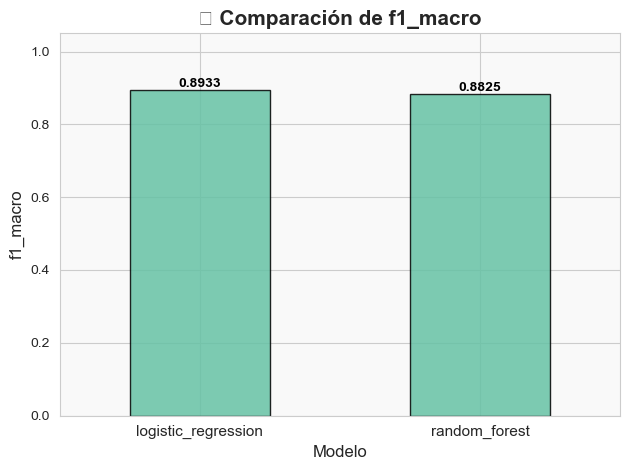

<Figure size 800x400 with 0 Axes>

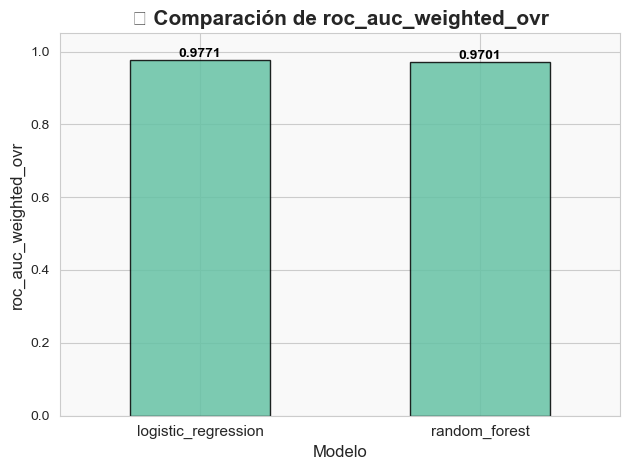

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
sns.set_palette("muted")

for metric in global_metrics:
    metric_values = (
        comparison_display[["model", metric]]
        .set_index("model")
    )
    
    plt.figure(figsize=(8,4))
    
    # Barras estilizadas
    ax = metric_values.plot(
        kind="bar",
        color=sns.color_palette("Set2", len(metric_values)),
        edgecolor="black",
        alpha=0.85,
        legend=False
    )
    
    # Títulos y etiquetas llamativas
    ax.set_title(f"✨ Comparación de {metric}", fontsize=15, fontweight="bold")
    ax.set_xlabel("Modelo", fontsize=12)
    ax.set_ylabel(metric, fontsize=12)
    ax.set_ylim(0, 1.05)
    ax.tick_params(axis="x", rotation=0, labelsize=11)
    
    # Etiquetas encima de cada barra
    for container in ax.containers:
        ax.bar_label(container, fmt="%.4f", fontsize=10, fontweight="bold", color="black")
    
    # Fondo claro
    plt.gca().set_facecolor("#f9f9f9")
    
    plt.tight_layout()
    plt.show()


### Interpretación inicial

La Regresión Logística presenta el mejor resultado provisional en:

- Accuracy.
- Precision ponderada.
- Recall ponderado.
- F1 ponderado.
- F1 macro.
- ROC-AUC multiclase.

La diferencia con Random Forest es moderada, por lo que ambos modelos deberán mantenerse para el análisis detallado.

La selección definitiva todavía no debe realizarse porque falta:

- Revisar el desempeño por clase.
- Analizar las matrices de confusión.
- Revisar las probabilidades.
- Ajustar hiperparámetros.
- Evaluar una sola vez sobre el conjunto de prueba.

## 6. Preparación de métricas por modelo

El archivo JSON contiene: 

- Métricas globales.
- Reporte de clasificación.
- Matriz de confusión.
- Orden de las clases.

In [15]:
metrics_by_model = {
    item["model"]:item
    for item in metrics_data
}
print(metrics_by_model.keys())

dict_keys(['logistic_regression', 'random_forest'])


In [16]:
for model_name, model_metrics in metrics_by_model.items():
    print("\n"+"="*60)
    print(model_name)
    print("="*60)

    report_df = pd.DataFrame(
        model_metrics["classification_report"]
    ).T

    display(
        report_df.round(4)
    )


logistic_regression


,precision,recall,f1-score,support
high,0.8549,0.9066,0.8800,182.0000
low,0.9266,0.9449,0.9357,254.0000
medium,0.8889,0.8407,0.8641,295.0000
accuracy,0.8933,0.8933,0.8933,0.8933
macro avg,0.8902,0.8974,0.8933,731.0000
weighted avg,0.8935,0.8933,0.8929,731.0000



random_forest


,precision,recall,f1-score,support
high,0.8446,0.8956,0.8693,182.0000
low,0.9222,0.9331,0.9276,254.0000
medium,0.8719,0.8305,0.8507,295.0000
accuracy,0.8824,0.8824,0.8824,0.8824
macro avg,0.8795,0.8864,0.8825,731.0000
weighted avg,0.8826,0.8824,0.8821,731.0000
